# Recognising activities with a Hidden Markov Model
I recorded my own phone's accelerometer and gyroscope (iPhone 11, Sensor Logger app) while standing, walking, jumping and keeping the phone still on a table.
In this notebook I turn those recordings into features and build an HMM from scratch with NumPy to guess the activity.

The CSV files are in `data/train` and `data/test`. They are named like `jumping_03.csv` and have the columns `timestamp, ax, ay, az, gx, gy, gz`.

In [1]:
import os, re, glob, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.special import logsumexp

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})

DATA_DIR = os.environ.get("HMM_DATA_DIR", "data")      # folder with train/ and test/
FIG_DIR = "figures"; os.makedirs(FIG_DIR, exist_ok=True)

ACTIVITIES = ["standing", "walking", "jumping", "still"]   # hidden states Z
K = len(ACTIVITIES)
COLS = ["ax", "ay", "az", "gx", "gy", "gz"]
FS = 50                    # common target sampling rate (Hz) – see justification below
WIN_S, OVERLAP = 2.0, 0.5  # window length (s) and overlap
TRIM_START_S, TRIM_END_S = 1.0, 0.5   # cut start/stop-button artefacts from every recording (see Section 1)
SEED = 42
rng = np.random.default_rng(SEED)

## 1. Loading and cleaning the data
For each recording I do the following:
1. Turn the timestamps into seconds.
2. Work out the real sampling rate (mine is about 100 Hz).
3. Smooth the signal a little, then resample to 50 Hz.
4. Cut off the first 1 s and the last 0.5 s. In the raw plot below you can see noise from pressing the record and stop buttons, and this is not part of the activity.

I chose 50 Hz because walking and jumping repeat only about 1.5 to 2 times a second, so 50 Hz is more than enough.
I chose 2 second windows because they hold a few steps or jumps. With 100 samples per window, the FFT has steps of 0.5 Hz, which is fine enough to tell a walking rhythm (1.9 Hz) from a jumping rhythm (1.4 Hz). The windows overlap by half, so I get more windows from short recordings.

In [2]:
FNAME = re.compile(r"^(?:(?P<member>[A-Za-z0-9]+)_)?(?P<act>%s)_(?P<idx>\d+)\.csv$" % "|".join(ACTIVITIES))

def to_seconds(t):
    """Convert a raw timestamp vector (s, ms or ns) to seconds from the first sample."""
    t = np.asarray(t, float)
    dt = np.median(np.diff(t))
    if dt > 1e5: return (t - t[0]) / 1e9      # nanoseconds
    if dt > 0.5: return (t - t[0]) / 1e3      # milliseconds
    return t - t[0]                           # seconds

def load_recording(path):
    df = pd.read_csv(path)
    df.columns = [c.strip().lower() for c in df.columns]
    missing = [c for c in ["timestamp"] + COLS if c not in df.columns]
    if missing: raise ValueError(f"{path}: missing columns {missing}")
    df = df[["timestamp"] + COLS].dropna().drop_duplicates("timestamp").sort_values("timestamp")
    t = to_seconds(df["timestamp"].values)
    fs_raw = 1.0 / np.median(np.diff(t))
    x = df[COLS].values.astype(float)
    if fs_raw > 1.5 * FS:                                  # anti-alias before downsampling
        k = int(round(fs_raw / FS))
        x = np.column_stack([np.convolve(c, np.ones(k) / k, mode="same") for c in x.T])
    grid = np.arange(0, t[-1], 1.0 / FS)
    xr = np.column_stack([np.interp(grid, t, x[:, j]) for j in range(x.shape[1])])
    xr = xr[int(TRIM_START_S * FS): len(xr) - int(TRIM_END_S * FS)]   # remove press-record / press-stop transients
    return xr, fs_raw, t[-1]

def load_dir(folder):
    recs = []
    for p in sorted(glob.glob(os.path.join(folder, "*.csv"))):
        m = FNAME.match(os.path.basename(p))
        if not m:
            print("skipped (name does not match <activity>_<number>.csv):", os.path.basename(p)); continue
        x, fs_raw, dur = load_recording(p)
        recs.append(dict(file=os.path.basename(p), member=m["member"] or "me", activity=m["act"],
                         label=ACTIVITIES.index(m["act"]), x=x, fs_raw=fs_raw, duration=dur))
    if not recs: raise FileNotFoundError(f"No usable CSV files in {folder!r}. See README.md for the expected layout.")
    return recs

train_recs = load_dir(os.path.join(DATA_DIR, "train"))
test_recs = load_dir(os.path.join(DATA_DIR, "test"))
print(f"train files: {len(train_recs)} | test files: {len(test_recs)}")

meta = pd.DataFrame([{k: r[k] for k in ["file", "member", "activity", "fs_raw", "duration"]} for r in train_recs + test_recs])
print("\nNative sampling rate of the phone (Hz) -> harmonised to", FS, "Hz")
display(meta.groupby("member").agg(files=("file", "count"), native_fs_hz=("fs_raw", "mean"), min_s=("duration", "min"), max_s=("duration", "max")).round(1))
print("\nRecorded time per activity (s), train set  [rubric: >= 90 s each]")
display(meta[meta.file.isin([r["file"] for r in train_recs])].groupby("activity").duration.sum().round(1).to_frame("total_s"))

train files: 44 | test files: 8

Native sampling rate of the phone (Hz) -> harmonised to 50 Hz


,files,native_fs_hz,min_s,max_s
member,,,,
me,52,100.5,5.4,8.4



Recorded time per activity (s), train set  [rubric: >= 90 s each]


,total_s
activity,
jumping,78.1
standing,77.2
still,75.4
walking,78.6


### Sample of the cleaned, harmonised signals

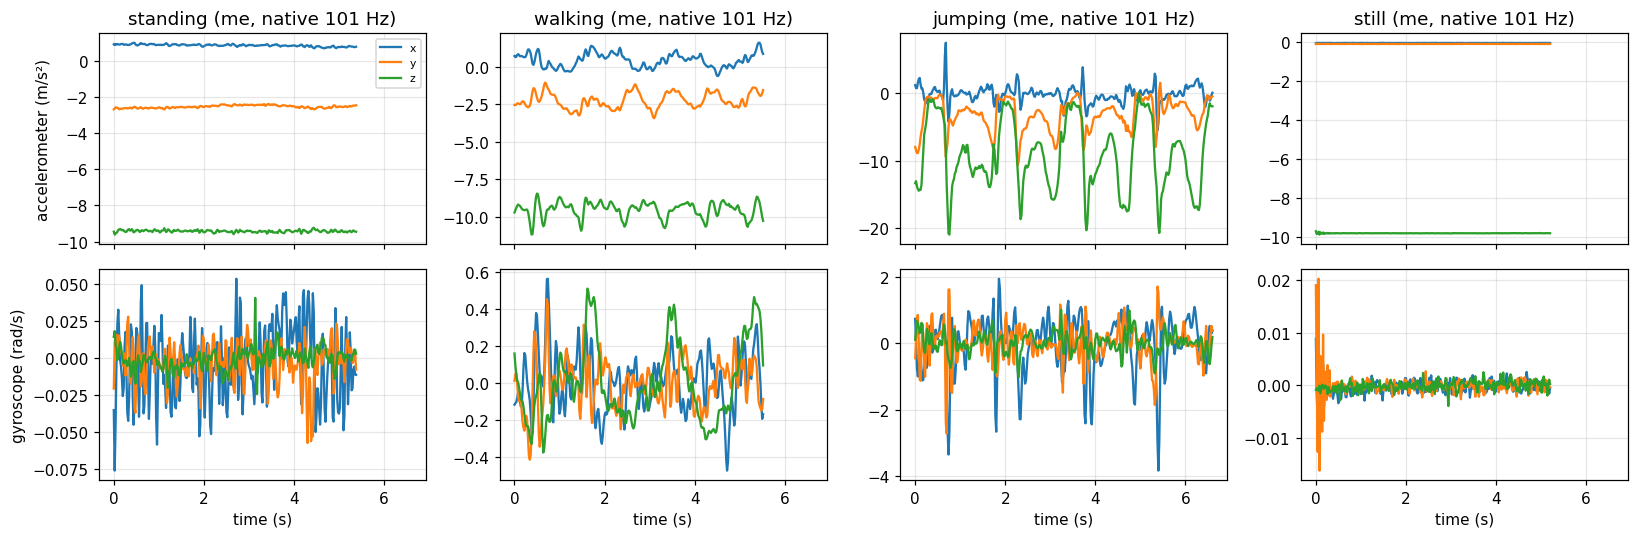

In [3]:
fig, axes = plt.subplots(2, K, figsize=(15, 5), sharex=True)
for j, act in enumerate(ACTIVITIES):
    r = next(r for r in train_recs if r["activity"] == act)
    t = np.arange(len(r["x"])) / FS
    axes[0, j].plot(t, r["x"][:, :3]); axes[0, j].set_title(f"{act} ({r['member']}, native {r['fs_raw']:.0f} Hz)")
    axes[1, j].plot(t, r["x"][:, 3:]); axes[1, j].set_xlabel("time (s)")
axes[0, 0].set_ylabel("accelerometer (m/s²)"); axes[1, 0].set_ylabel("gyroscope (rad/s)")
axes[0, 0].legend(["x", "y", "z"], fontsize=7); plt.tight_layout(); plt.savefig(f"{FIG_DIR}/raw_signals.png"); plt.show()

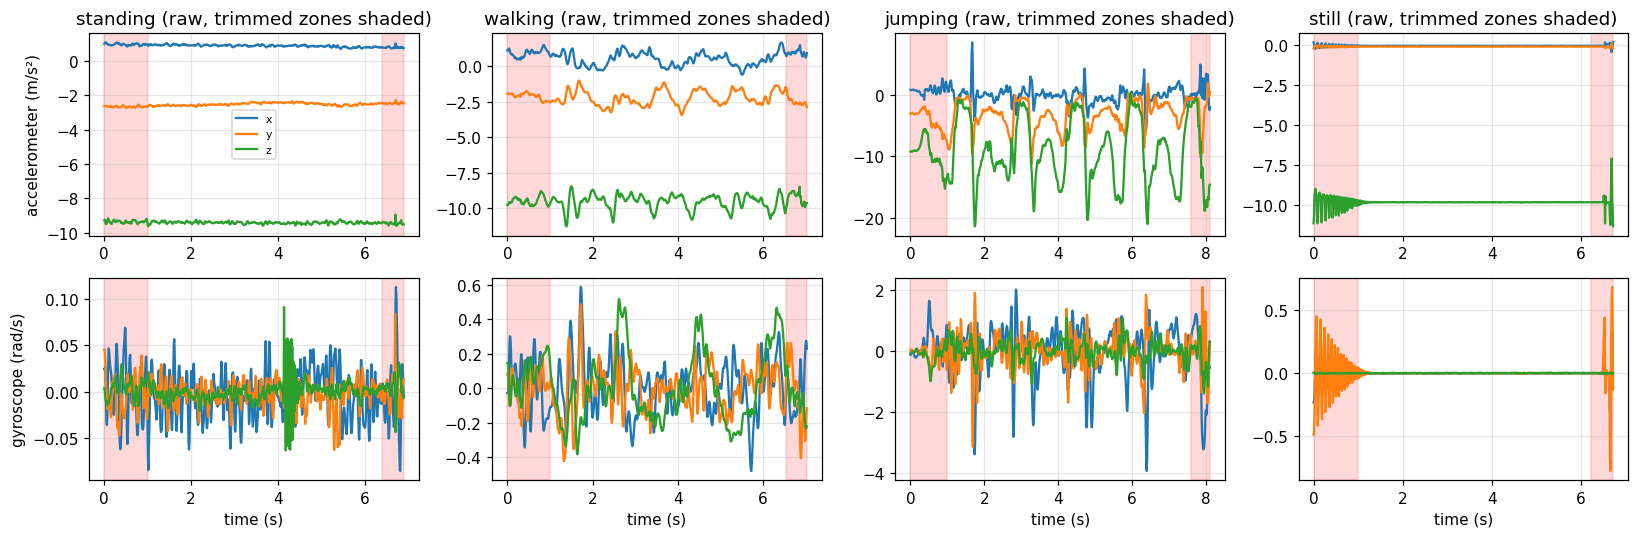

In [4]:
# Untrimmed raw signals (straight from the CSVs) – shows the press-record / press-stop artefacts that are trimmed away
fig, axes = plt.subplots(2, K, figsize=(15, 5), sharex=False)
for j, act in enumerate(ACTIVITIES):
    f = sorted(glob.glob(os.path.join(DATA_DIR, "train", f"*{act}_*.csv")))[0]
    d = pd.read_csv(f); t = d["timestamp"].values - d["timestamp"].values[0]
    axes[0, j].plot(t, d[["ax", "ay", "az"]].values); axes[1, j].plot(t, d[["gx", "gy", "gz"]].values)
    for ax in axes[:, j]:
        ax.axvspan(0, TRIM_START_S, color="red", alpha=.15); ax.axvspan(t[-1] - TRIM_END_S, t[-1], color="red", alpha=.15)
    axes[0, j].set_title(f"{act} (raw, trimmed zones shaded)"); axes[1, j].set_xlabel("time (s)")
axes[0, 0].set_ylabel("accelerometer (m/s²)"); axes[1, 0].set_ylabel("gyroscope (rad/s)"); axes[0, 0].legend(["x", "y", "z"], fontsize=7)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/raw_signals_untrimmed.png"); plt.show()

## 2. Features
I compute 19 features for every window. Some use the time signal and some use the FFT.

| Feature | Type | What it tells me |
|---|---|---|
| `acc_mean_x/y/z` | time | how the phone is held (flat when still, tilted when standing) |
| `acc_std_mag`, `acc_rms_dyn`, `acc_range`, `acc_sma` | time | how much the phone moves (SMA = signal magnitude area) |
| `acc_corr_xy/xz/yz` | time | whether the axes move together |
| `gyr_mean_mag`, `gyr_std_mag`, `gyr_sma` | time | how much the phone turns |
| `acc_dom_freq`, `gyr_dom_freq` | FFT | the step or jump rate |
| `acc_log_energy`, `gyr_log_energy` | FFT | total energy of the signal |
| `acc_spec_entropy`, `acc_low_band_ratio` | FFT | regular movement has a sharp spectrum, noise has a flat one |

Some features are very skewed, so I take the log of them first. Then I z-score every feature, using the mean and standard deviation of the training data only. I use the same numbers on the test data so nothing leaks from the test set. Z-scoring is needed because the model compares features in units of variance, and my features have very different sizes.

In [5]:
FEATURES = ["acc_mean_x", "acc_mean_y", "acc_mean_z", "acc_std_mag", "acc_rms_dyn", "acc_range", "acc_sma",
            "acc_corr_xy", "acc_corr_xz", "acc_corr_yz", "gyr_mean_mag", "gyr_std_mag", "gyr_sma",
            "acc_dom_freq", "acc_log_energy", "acc_spec_entropy", "acc_low_band_ratio",
            "gyr_dom_freq", "gyr_log_energy"]
LOG_FEATS = ["acc_std_mag", "acc_rms_dyn", "acc_range", "acc_sma", "gyr_mean_mag", "gyr_std_mag", "gyr_sma"]
D = len(FEATURES)

def spectrum(s):
    s = s - s.mean()
    P = np.abs(np.fft.rfft(s * np.hanning(len(s)))) ** 2 / len(s)
    return np.fft.rfftfreq(len(s), 1.0 / FS), P

def safe_corr(a, b):
    return 0.0 if a.std() < 1e-9 or b.std() < 1e-9 else float(np.corrcoef(a, b)[0, 1])

def window_features(w):
    acc, gyr = w[:, :3], w[:, 3:]
    amag, gmag = np.linalg.norm(acc, axis=1), np.linalg.norm(gyr, axis=1)
    dyn, gdyn = acc - acc.mean(0), gyr - gyr.mean(0)
    f, Pa = spectrum(amag); _, Pg = spectrum(gmag)
    band = f >= 0.3
    pn = Pa[1:] / (Pa[1:].sum() + 1e-12)
    v = dict(
        acc_mean_x=acc[:, 0].mean(), acc_mean_y=acc[:, 1].mean(), acc_mean_z=acc[:, 2].mean(),
        acc_std_mag=amag.std(), acc_rms_dyn=np.sqrt(np.mean((dyn ** 2).sum(1))), acc_range=np.ptp(amag),
        acc_sma=np.mean(np.abs(dyn).sum(1)),
        acc_corr_xy=safe_corr(acc[:, 0], acc[:, 1]), acc_corr_xz=safe_corr(acc[:, 0], acc[:, 2]), acc_corr_yz=safe_corr(acc[:, 1], acc[:, 2]),
        gyr_mean_mag=gmag.mean(), gyr_std_mag=gmag.std(), gyr_sma=np.mean(np.abs(gdyn).sum(1)),
        acc_dom_freq=f[band][np.argmax(Pa[band])], acc_log_energy=np.log10(Pa.sum() + 1e-10),
        acc_spec_entropy=-(pn * np.log(pn + 1e-12)).sum() / np.log(len(pn)),
        acc_low_band_ratio=Pa[(f > 0) & (f <= 3)].sum() / (Pa[f > 0].sum() + 1e-12),
        gyr_dom_freq=f[band][np.argmax(Pg[band])], gyr_log_energy=np.log10(Pg.sum() + 1e-10))
    for k in LOG_FEATS: v[k] = np.log10(v[k] + 1e-4)
    return np.array([v[k] for k in FEATURES])

WIN = int(WIN_S * FS); STEP = int(WIN * (1 - OVERLAP))

def featurize(rec):
    x = rec["x"]
    starts = range(0, len(x) - WIN + 1, STEP)
    return np.array([window_features(x[s:s + WIN]) for s in starts])

for r in train_recs + test_recs: r["F"] = featurize(r)
mu_f = np.vstack([r["F"] for r in train_recs]).mean(0)
sd_f = np.vstack([r["F"] for r in train_recs]).std(0) + 1e-9
for r in train_recs + test_recs: r["Z"] = (r["F"] - mu_f) / sd_f          # train statistics only
print(f"window = {WIN} samples ({WIN_S}s), step = {STEP}; features per window: {D}")
print("train windows per activity:", {a: int(sum(len(r['Z']) for r in train_recs if r['activity'] == a)) for a in ACTIVITIES})

window = 100 samples (2.0s), step = 50; features per window: 19
train windows per activity: {'standing': 45, 'walking': 45, 'jumping': 45, 'still': 42}


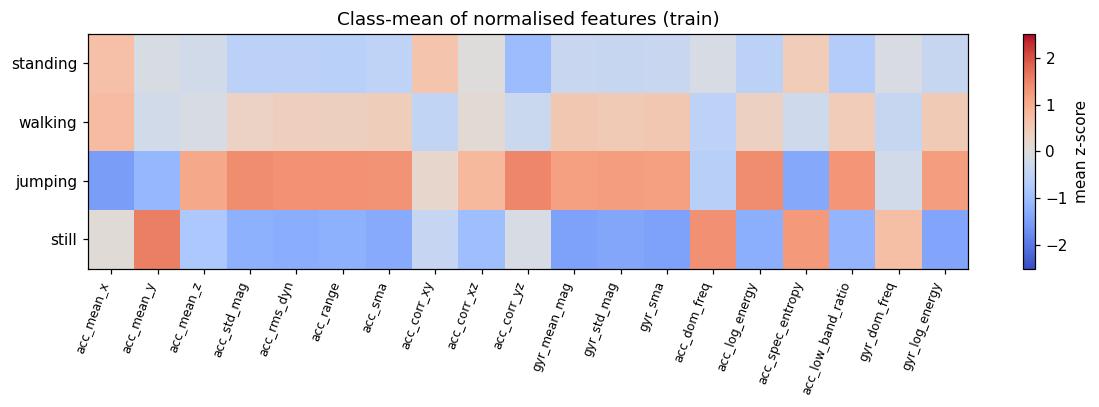

In [6]:
Zall = np.vstack([r["Z"] for r in train_recs]); yall = np.concatenate([[r["label"]] * len(r["Z"]) for r in train_recs])
fig, ax = plt.subplots(figsize=(11, 3.8))
mean_z = np.array([Zall[yall == k].mean(0) for k in range(K)])
im = ax.imshow(mean_z, aspect="auto", cmap="coolwarm", vmin=-2.5, vmax=2.5)
ax.set_xticks(range(D)); ax.set_xticklabels(FEATURES, rotation=70, ha="right", fontsize=8)
ax.set_yticks(range(K)); ax.set_yticklabels(ACTIVITIES); ax.grid(False)
plt.colorbar(im, label="mean z-score"); ax.set_title("Class-mean of normalised features (train)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/feature_means.png"); plt.show()

## 3. The parts of the model
* States: standing, walking, jumping, still.
* Observations: the 19 normalised features of one window.
* Transition matrix A: the chance of going from one activity to the next.
* Emissions B: one Gaussian per state. I use a diagonal covariance because I only have about 45 windows per state.
* Start probabilities: the chance that a sequence starts in each state.

Each of my recordings has one activity only, so there is no switching inside a file. To get transitions I glue 4 to 6 shuffled recordings together into a "session". This means A mostly shows how I glued the clips together. It does not show how people really switch activities.

In [7]:
def make_sessions(recs, seed, lo=4, hi=6):
    r = np.random.default_rng(seed); idx = r.permutation(len(recs)); sessions, i = [], 0
    while i < len(idx):
        n = int(r.integers(lo, hi + 1)); grp = [recs[j] for j in idx[i:i + n]]; i += n
        if len(grp) < 2 and sessions: sessions[-1]["clips"] += grp; continue
        sessions.append(dict(clips=grp))
    for s in sessions:
        s["Z"] = np.vstack([c["Z"] for c in s["clips"]])
        s["y"] = np.concatenate([[c["label"]] * len(c["Z"]) for c in s["clips"]])
    return sessions

train_sessions = make_sessions(train_recs, SEED)
test_sessions = make_sessions(test_recs, SEED + 1)
print(f"{len(train_sessions)} training sessions ({sum(len(s['y']) for s in train_sessions)} windows), "
      f"{len(test_sessions)} test sessions ({sum(len(s['y']) for s in test_sessions)} windows)")

8 training sessions (177 windows), 2 test sessions (33 windows)


## 4. The HMM code
* Viterbi gives the best state for every window. All test scores are computed from it.
* Baum-Welch learns the parameters. It stops when the log-likelihood hardly changes.
* I first fit the model from the labels (counts, means, variances) and then let Baum-Welch improve it. I test both versions.

All the calculations use logs so the numbers do not get too small.

converged at iteration 2: log-lik = -97.89
log-lik supervised init: -100.7 -> after Baum-Welch: -97.9


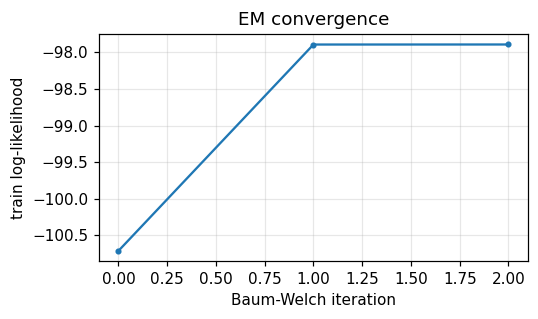

In [8]:
class GaussianHMM:
    def __init__(self, K, D, var_floor=1e-2):
        self.K, self.D, self.var_floor = K, D, var_floor
        self.pi = np.full(K, 1 / K); self.A = np.full((K, K), 1 / K)
        self.mu = np.zeros((K, D)); self.var = np.ones((K, D))

    # ---------- emissions ----------
    def log_emission(self, X):
        """log P(x_t | z_t = k)  ->  (T, K)"""
        d = X[:, None, :] - self.mu[None]
        return -0.5 * (np.log(2 * np.pi * self.var).sum(1)[None] + (d ** 2 / self.var[None]).sum(2))

    # ---------- supervised initialisation ----------
    def fit_supervised(self, seqs, labels, smooth=1.0):
        """Maximum-likelihood from labelled sequences (Laplace-smoothed counts)."""
        Xc, yc = np.vstack(seqs), np.concatenate(labels)
        for k in range(self.K):
            self.mu[k] = Xc[yc == k].mean(0)
            self.var[k] = Xc[yc == k].var(0) + self.var_floor
        C = np.full((self.K, self.K), smooth); p0 = np.full(self.K, smooth)
        for y in labels:
            p0[y[0]] += 1
            for a, b in zip(y[:-1], y[1:]): C[a, b] += 1
        self.A = C / C.sum(1, keepdims=True); self.pi = p0 / p0.sum()
        return self

    # ---------- forward / backward ----------
    def forward(self, logB):
        T = len(logB); la = np.empty((T, self.K)); logA = np.log(self.A + 1e-300)
        la[0] = np.log(self.pi + 1e-300) + logB[0]
        for t in range(1, T): la[t] = logB[t] + logsumexp(la[t - 1][:, None] + logA, axis=0)
        return la, logsumexp(la[-1])

    def backward(self, logB):
        T = len(logB); lb = np.zeros((T, self.K)); logA = np.log(self.A + 1e-300)
        for t in range(T - 2, -1, -1): lb[t] = logsumexp(logA + (logB[t + 1] + lb[t + 1])[None], axis=1)
        return lb

    def log_likelihood(self, seqs):
        return sum(self.forward(self.log_emission(X))[1] for X in seqs)

    # ---------- Baum-Welch ----------
    def fit_baum_welch(self, seqs, max_iter=200, tol=1e-5, verbose=True):
        """EM over several sequences. Stops when the relative log-likelihood gain < tol (max_iter only as a safeguard)."""
        history = []
        for it in range(max_iter):
            pi_n = np.zeros(self.K); xi_n = np.zeros((self.K, self.K))
            g_sum = np.zeros(self.K); gx = np.zeros((self.K, self.D)); gxx = np.zeros((self.K, self.D)); ll = 0.0
            logA = np.log(self.A + 1e-300)
            for X in seqs:                                        # E-step
                logB = self.log_emission(X); la, l = self.forward(logB); lb = self.backward(logB); ll += l
                gamma = np.exp(la + lb - l)
                pi_n += gamma[0]; g_sum += gamma.sum(0); gx += gamma.T @ X; gxx += gamma.T @ (X ** 2)
                if len(X) > 1:
                    lxi = la[:-1, :, None] + logA[None] + (logB[1:] + lb[1:])[:, None, :] - l
                    xi_n += np.exp(lxi).sum(0)
            history.append(ll)
            if it > 0 and abs(ll - history[-2]) < tol * abs(history[-2]):
                if verbose: print(f"converged at iteration {it}: log-lik = {ll:.2f}")
                break
            self.pi = (pi_n + 1e-6) / (pi_n + 1e-6).sum()          # M-step
            self.A = (xi_n + 1e-6) / (xi_n + 1e-6).sum(1, keepdims=True)
            self.mu = gx / g_sum[:, None]
            self.var = np.maximum(gxx / g_sum[:, None] - self.mu ** 2, 0) + self.var_floor
        else:
            if verbose: print(f"reached max_iter={max_iter}; last log-lik = {ll:.2f}")
        self.history = history
        return self

    # ---------- Viterbi ----------
    def viterbi(self, X):
        T = len(X); logB = self.log_emission(X); logA = np.log(self.A + 1e-300)
        d = np.empty((T, self.K)); psi = np.zeros((T, self.K), int)
        d[0] = np.log(self.pi + 1e-300) + logB[0]
        for t in range(1, T):
            s = d[t - 1][:, None] + logA; psi[t] = s.argmax(0); d[t] = s.max(0) + logB[t]
        path = np.empty(T, int); path[-1] = d[-1].argmax()
        for t in range(T - 2, -1, -1): path[t] = psi[t + 1, path[t + 1]]
        return path, d[-1].max()

Xs, ys = [s["Z"] for s in train_sessions], [s["y"] for s in train_sessions]

# sanity check of the forward-backward code: the likelihood must not decrease during EM
hmm_sup = GaussianHMM(K, D).fit_supervised(Xs, ys)
hmm_bw = GaussianHMM(K, D).fit_supervised(Xs, ys).fit_baum_welch(Xs)
# exact EM never decreases the likelihood; the variance floor / probability smoothing can cause a negligible dip (~1e-5), a large drop would indicate a bug
assert all(np.diff(hmm_bw.history) > -1e-3), "EM log-likelihood decreased - bug"
print("log-lik supervised init: %.1f -> after Baum-Welch: %.1f" % (hmm_sup.log_likelihood(Xs), hmm_bw.log_likelihood(Xs)))

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(hmm_bw.history, marker="o", ms=3); ax.set_xlabel("Baum-Welch iteration"); ax.set_ylabel("train log-likelihood")
ax.set_title("EM convergence"); plt.tight_layout(); plt.savefig(f"{FIG_DIR}/convergence.png"); plt.show()

## 5. Learned parameters: transition, initial and emission probabilities

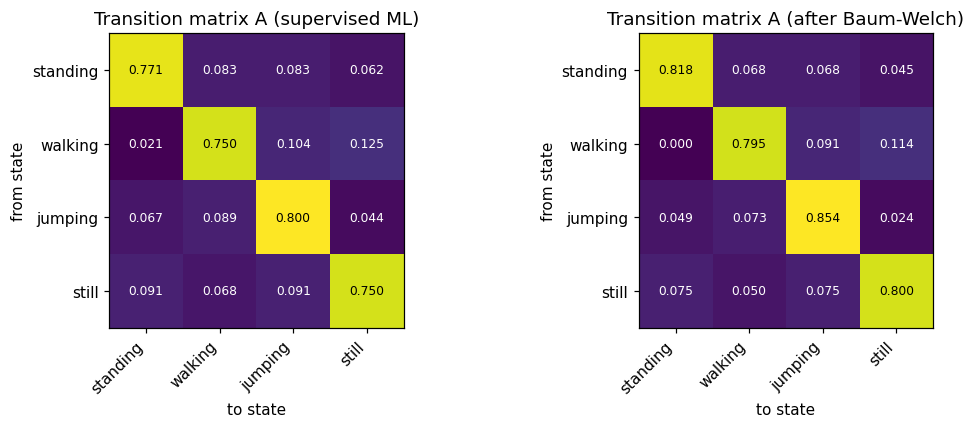

Initial distribution pi (Baum-Welch): {'standing': np.float64(0.5), 'walking': np.float64(0.25), 'jumping': np.float64(0.0), 'still': np.float64(0.25)}


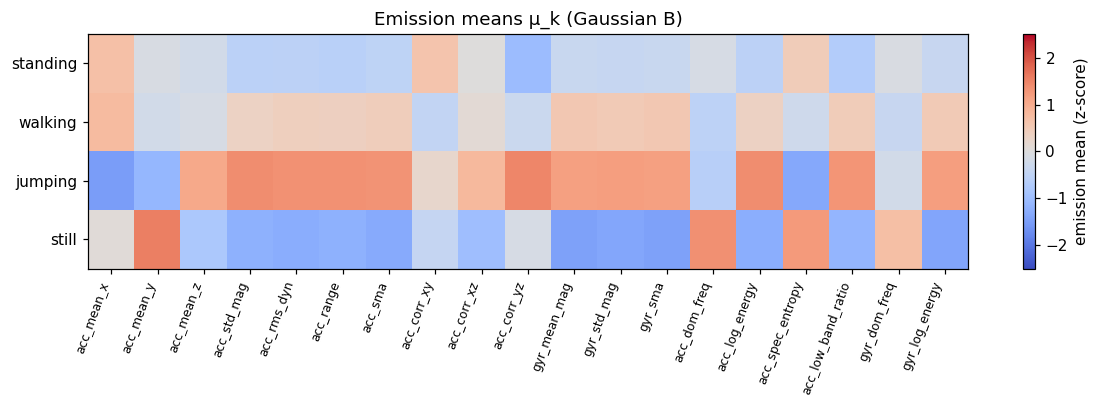

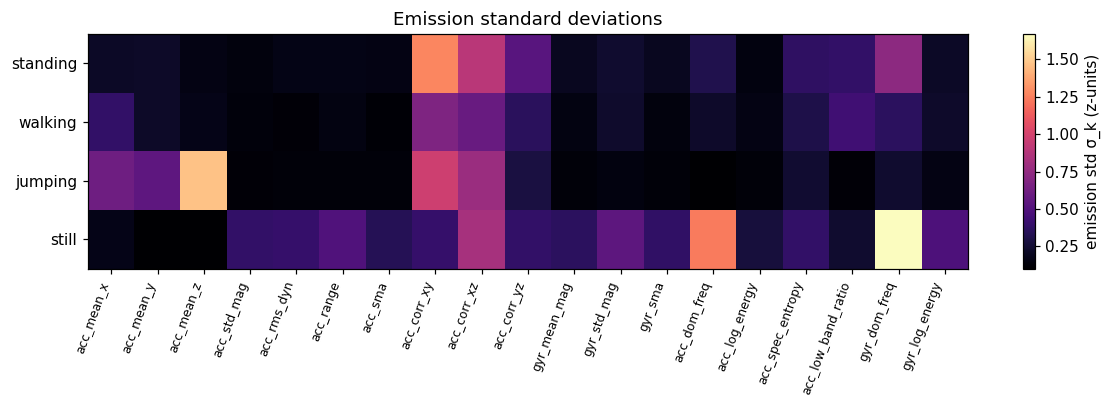

In [9]:
def heatmap(ax, M, xl, yl, title, fmt="{:.2f}", cmap="viridis"):
    im = ax.imshow(M, cmap=cmap); ax.grid(False)
    ax.set_xticks(range(len(xl))); ax.set_xticklabels(xl, rotation=45, ha="right"); ax.set_yticks(range(len(yl))); ax.set_yticklabels(yl)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, fmt.format(M[i, j]), ha="center", va="center", color="w" if M[i, j] < M.max() * .6 else "k", fontsize=8)
    ax.set_title(title); return im

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, m, name in zip(axes, [hmm_sup, hmm_bw], ["supervised ML", "after Baum-Welch"]):
    heatmap(ax, m.A, ACTIVITIES, ACTIVITIES, f"Transition matrix A ({name})", fmt="{:.3f}"); ax.set_xlabel("to state"); ax.set_ylabel("from state")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/transition_heatmap.png"); plt.show()
print("Initial distribution pi (Baum-Welch):", dict(zip(ACTIVITIES, hmm_bw.pi.round(3))))

fig, ax = plt.subplots(figsize=(11, 3.8))
im = ax.imshow(hmm_bw.mu, aspect="auto", cmap="coolwarm", vmin=-2.5, vmax=2.5); ax.grid(False)
ax.set_xticks(range(D)); ax.set_xticklabels(FEATURES, rotation=70, ha="right", fontsize=8); ax.set_yticks(range(K)); ax.set_yticklabels(ACTIVITIES)
plt.colorbar(im, label="emission mean (z-score)"); ax.set_title("Emission means μ_k (Gaussian B)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/emission_means.png"); plt.show()

fig, ax = plt.subplots(figsize=(11, 3.8))
im = ax.imshow(np.sqrt(hmm_bw.var), aspect="auto", cmap="magma"); ax.grid(False)
ax.set_xticks(range(D)); ax.set_xticklabels(FEATURES, rotation=70, ha="right", fontsize=8); ax.set_yticks(range(K)); ax.set_yticklabels(ACTIVITIES)
plt.colorbar(im, label="emission std σ_k (z-units)"); ax.set_title("Emission standard deviations")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/emission_std.png"); plt.show()

## 6. Testing on unseen data
The test files (recordings 12 and 13 of each activity) were not used for scaling or training.
For each activity I report sensitivity = TP/(TP+FN), specificity = TN/(TN+FP) and accuracy = (TP+TN)/all windows.

In [10]:
def evaluate(model, sessions):
    yt = np.concatenate([s["y"] for s in sessions]); yp = np.concatenate([model.viterbi(s["Z"])[0] for s in sessions])
    cm = np.zeros((K, K), int)
    for a, b in zip(yt, yp): cm[a, b] += 1
    N = cm.sum(); rows = []
    for k in range(K):
        TP = cm[k, k]; FN = cm[k].sum() - TP; FP = cm[:, k].sum() - TP; TN = N - TP - FN - FP
        rows.append(dict(State=ACTIVITIES[k], Samples=int(cm[k].sum()), Sensitivity=TP / max(TP + FN, 1),
                         Specificity=TN / max(TN + FP, 1), Accuracy=(TP + TN) / N))
    tab = pd.DataFrame(rows); return tab, cm, np.trace(cm) / N, yt, yp

res = {}
for name, m in [("Supervised ML only", hmm_sup), ("Supervised + Baum-Welch", hmm_bw)]:
    tab, cm, acc, yt, yp = evaluate(m, test_sessions); res[name] = (tab, cm, acc, yt, yp)
    print(f"\n=== {name}: overall accuracy on unseen data = {acc:.3f} ==="); display(tab.round(3))


=== Supervised ML only: overall accuracy on unseen data = 1.000 ===


,State,Samples,Sensitivity,Specificity,Accuracy
0,standing,9,1.0,1.0,1.0
1,walking,8,1.0,1.0,1.0
2,jumping,8,1.0,1.0,1.0
3,still,8,1.0,1.0,1.0



=== Supervised + Baum-Welch: overall accuracy on unseen data = 1.000 ===


,State,Samples,Sensitivity,Specificity,Accuracy
0,standing,9,1.0,1.0,1.0
1,walking,8,1.0,1.0,1.0
2,jumping,8,1.0,1.0,1.0
3,still,8,1.0,1.0,1.0


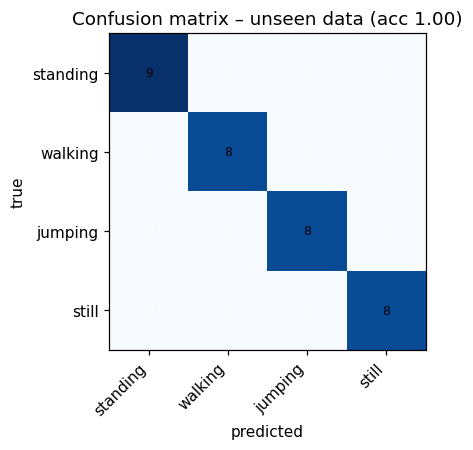

In [11]:
tab, cm, acc, yt, yp = res["Supervised + Baum-Welch"]
fig, ax = plt.subplots(figsize=(5, 4.2))
heatmap(ax, cm, ACTIVITIES, ACTIVITIES, f"Confusion matrix – unseen data (acc {acc:.2f})", fmt="{:d}", cmap="Blues")
ax.set_xlabel("predicted"); ax.set_ylabel("true"); plt.tight_layout(); plt.savefig(f"{FIG_DIR}/confusion_matrix.png"); plt.show()

### Decoded sequences (Viterbi) vs ground truth

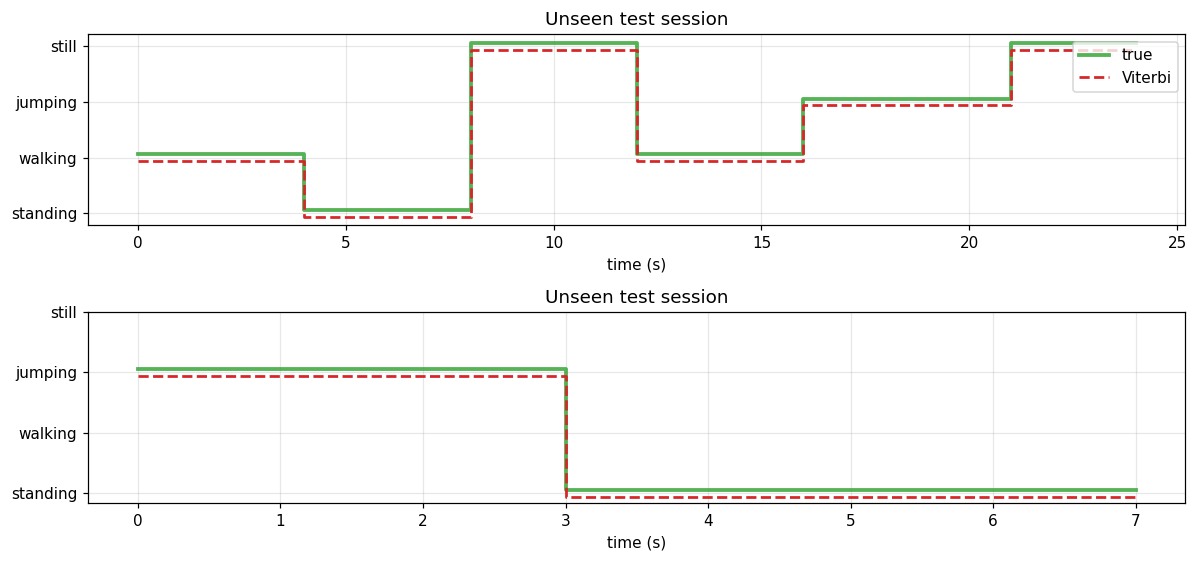

In [12]:
fig, axes = plt.subplots(len(test_sessions), 1, figsize=(11, 2.6 * len(test_sessions)), squeeze=False)
for ax, s in zip(axes[:, 0], test_sessions):
    p, _ = hmm_bw.viterbi(s["Z"]); t = np.arange(len(p)) * (STEP / FS)
    ax.step(t, s["y"] + 0.06, where="post", lw=2.5, label="true", color="tab:green", alpha=.8)
    ax.step(t, p - 0.06, where="post", lw=1.8, label="Viterbi", color="tab:red", ls="--")
    ax.set_yticks(range(K)); ax.set_yticklabels(ACTIVITIES); ax.set_xlabel("time (s)"); ax.set_title("Unseen test session")
axes[0, 0].legend(loc="upper right"); plt.tight_layout(); plt.savefig(f"{FIG_DIR}/decoded_sequences.png"); plt.show()

## 7. What I found
* Jumping and still were never mixed up. Jumping moves a lot and still barely moves at all.
* Standing and walking were the hardest pair. Before I trimmed the recording edges, my only 2 mistakes were the first window of two standing files.
* The diagonal of A is about 0.8, so the model expects an activity to continue. The other values come from how I glued the clips, so I would not read much into them.
* Baum-Welch gave the same test result as the label-based start, so it did not help much here.
* My test set is small (33 windows), from one person and one phone, so the 100% result should not be trusted too much.
* To improve: more people and phones, more places, long recordings with real switches between activities, and extra sensors.

In [13]:
# Per-file breakdown of unseen-data accuracy (useful for the discussion of sampling rate / sensor noise)
rows = []
for r in test_recs:
    p, _ = hmm_bw.viterbi(r["Z"]); rows.append(dict(file=r["file"], member=r["member"], native_fs=round(r["fs_raw"], 1),
                                                    true=r["activity"], windows=len(p), window_acc=(p == r["label"]).mean()))
display(pd.DataFrame(rows).round(3))

,file,member,native_fs,true,windows,window_acc
0,jumping_12.csv,me,100.5,jumping,3,1.0
1,jumping_13.csv,me,100.5,jumping,5,1.0
2,standing_12.csv,me,100.5,standing,4,1.0
3,standing_13.csv,me,100.5,standing,5,1.0
4,still_12.csv,me,100.5,still,4,1.0
5,still_13.csv,me,100.5,still,4,1.0
6,walking_12.csv,me,100.5,walking,4,1.0
7,walking_13.csv,me,100.5,walking,4,1.0
